In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle
from scipy.signal import find_peaks


sys.path.insert(0, "./cellular_cycle")
sys.path.insert(0, "./figures")

import fracprolif as fp

from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction

In [2]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
sampled_parameter_names = np.loadtxt('./model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv('./model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [5]:
# Setting initial concentrations
initial_concentrations = pd.read_csv('./model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [6]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv(os.getcwd() + './model_data/ECM_conditions_2.csv')
ECM_conditions

,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


2026-06-11 15:33:23.120 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


<Axes: xlabel='Time (h)', ylabel='Concentration'>

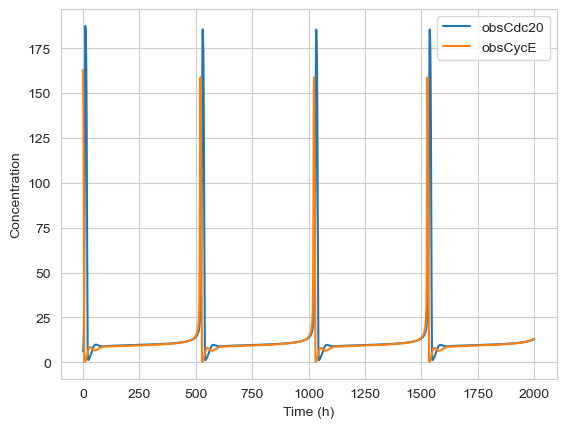

In [7]:
condition = "55 kPa erlotinib"

t = np.linspace(0, 20000, 200001)

model.parameters['AKT'].value = 0.6
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 1.0
model.parameters['CycDi_0'].value = 0.4

sim_ode = ScipyOdeSimulator(model, t, verbose=False).run() #deterministic simulation

observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,20000), legend=True)

<Axes: xlabel='Time (h)', ylabel='Concentration'>

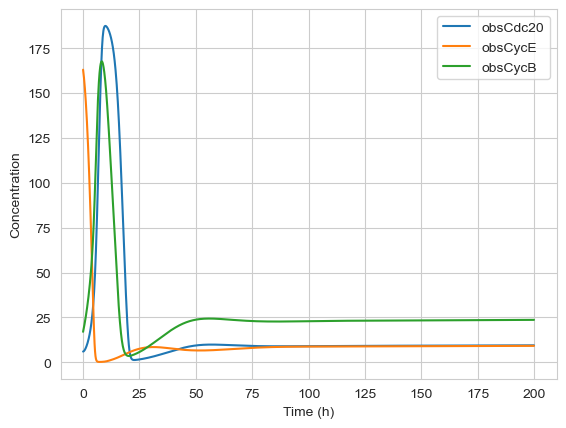

In [8]:
observables=['obsCdc20', 'obsCycE', 'obsCycB']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,2000), legend=True)

In [ ]:
t = np.linspace(0, 70000, 700001)
sim_stoch = BngSimulator(model, tspan=t, verbose=False)
prot = sim_stoch.run(method='ssa', verbose=False)

In [ ]:
observables=['obsCdc20', 'obsCycE']
plotObs(model=prot.all, obs=observables, times=t, tpos=range(0,20000), legend=True)

In [ ]:
def getIMT(prot):
    peaks_cdc, _ = find_peaks(prot.all['obsCdc20'], prominence=100, distance=100)
    IMTs = [t[y] - t[x] for x, y in zip(peaks_cdc, peaks_cdc[1:])]

    return IMTs

In [ ]:
IMTs = getIMT(prot)


In [ ]:
len(IMTs)

In [ ]:
min(IMTs)

In [9]:
init = 10
run_time = 500
observed_cells_time = 500
all_IMTs = []
n = 0

In [10]:
from call_cell_events import call_events #
from retrieve_cellState import retrieve_cellState #

In [11]:
def runIMTs(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, IMTs_count):
    all_IMTs = []
    n = 0
    while len(all_IMTs)<IMTs_count:
        check, population_df, cells, cell_count = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
        IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
        all_events_simulated = call_events(run_time, IMT_eoe_counts)

        mits = all_events_simulated.loc[all_events_simulated['event']=='mitosis'].reset_index()
        mits_list = mits['Lifespan'].tolist()
        mits_list_r = [round(x,1) for x in mits_list]

        IMT_tmp, s_m_tmp, g1_tmp = SMs_G1s_IMTs_extraction(cells)

        if n==0:
            all_IMTs = mits_list_r
            all_g1s = g1_tmp
        else:
            all_IMTs.extend(mits_list_r)
            all_g1s.extend(g1_tmp)

        # filename_cell_count = Path(SAVE_DIR, f'cell_counts_{condition}_{n}_cycdi_0_4.csv')
        # np.savetxt(filename_cell_count, cell_count, delimiter=',')

        n+=1
        print(len(all_IMTs))

    # filename_IMT = Path(SAVE_DIR, f'IMTs_{condition}_cycdi_500_0_4.csv')
    # filename_g1 = Path(SAVE_DIR, f'G1s_{condition}_cycdi_500_0_4.csv')
    # np.savetxt(filename_IMT, all_IMTs, delimiter=',')
    # np.savetxt(filename_g1, all_g1s, delimiter=',')
    return all_IMTs, all_g1s

In [13]:
# Run IMTs with cycdi and EGFRi
all_IMTs, all_g1s = runIMTs(10, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, 500)

55 kPa erlotinib
40
55 kPa erlotinib
102
55 kPa erlotinib
156
55 kPa erlotinib
211
55 kPa erlotinib
289
55 kPa erlotinib
343
55 kPa erlotinib
433
55 kPa erlotinib
497
55 kPa erlotinib
558


In [14]:
len(all_IMTs)

558

In [15]:
filename_IMT = Path(SAVE_DIR, f'IMTs_{condition}_cycdi_500_0_4.csv')
np.savetxt(filename_IMT, all_IMTs, delimiter=',')

2026-06-11 17:28:22.095 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


<Axes: xlabel='Time (h)', ylabel='Concentration'>

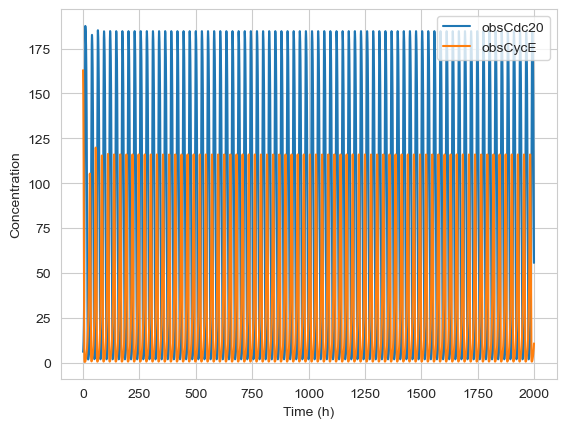

In [7]:
condition = "55 kPa erlotinib"

t = np.linspace(0, 20000, 200001)

model.parameters['AKT'].value = 0.6
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 1.0
model.parameters['CycDi_0'].value = 0.0

sim_ode = ScipyOdeSimulator(model, t, verbose=False).run() #deterministic simulation

observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,20000), legend=True)

In [12]:
# Run IMTs with EGFRi
all_IMTs_EGFRI, all_g1s = runIMTs(10, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, 500)

55 kPa erlotinib


PermissionError: [WinError 32] The process cannot access the file because it is being used by another process: 'C:\\Users\\olesk\\AppData\\Local\\Temp\\tmpBNG94482ko0\\pysb.bngl'

In [ ]:
filename_IMT = Path(SAVE_DIR, f'IMTs_{condition}_cycdi_500_0.csv')
np.savetxt(filename_IMT, all_IMTs_EGFRI, delimiter=',')